In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_SUBOR = Path("tabulka_dat.csv")
VLNOVA_DLZKA_NM = 532.0
VYSTUP = Path("vysledky_piezo")
VYSTUP.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 2. Načítanie dát


In [12]:
if not CSV_SUBOR.exists():
    raise FileNotFoundError(f"Súbor {CSV_SUBOR} musí byť v rovnakom priečinku ako notebook.")

df = pd.read_csv(CSV_SUBOR)

def najdi_stlpec(kluce):
    for col in df.columns:
        nazov = str(col).strip().lower().replace(" ", "_")
        if any(k in nazov for k in kluce):
            return col
    return None

def na_cislo(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

u_col = najdi_stlpec(("u_pp", "upp", "napat", "voltage", "u_[")) or df.columns[1]
n_col = najdi_stlpec(("pocet_pikov", "pocet_peak", "peak", "pik", "maxim")) or df.columns[2]
f_col = najdi_stlpec(("f_hz", "frekv", "frequency", "f_["))

data = pd.DataFrame({"U_pp_V": na_cislo(df[u_col]), "N_peakov": na_cislo(df[n_col])})
data = data.dropna().sort_values("U_pp_V").reset_index(drop=True)
if len(data) < 3:
    raise ValueError("Na regresiu sú potrebné aspoň tri platné merania.")

frekvencia = float(na_cislo(df[f_col]).dropna().mean()) if f_col else np.nan
display(data)
if np.isfinite(frekvencia):
    print(f"Frekvencia: {frekvencia:.4f} Hz")
    print(f"Perióda: {1000/frekvencia:.4f} ms")


,U_pp_V,N_peakov
0,4.76,1
1,6.16,2
2,7.82,2
3,8.59,2
4,10.05,3
5,11.41,3
6,11.83,3
7,12.04,4
8,13.00,4
9,14.24,5


Frekvencia: 101.4000 Hz
Perióda: 9.8619 ms


## 3. Lineárny fit $N=aU_{pp}+b$


N = (0.379012 ± 0.019255) U_pp + (-0.850511 ± 0.274286)
R² = 0.965125
RMSE = 0.394381 peaku


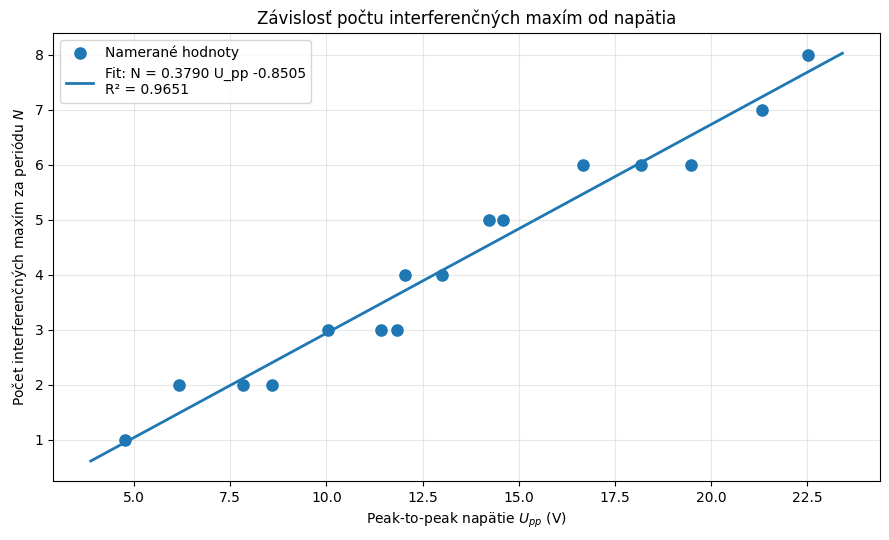

In [13]:
x = data["U_pp_V"].to_numpy(float)
y = data["N_peakov"].to_numpy(float)
n = len(x)
X = np.column_stack([x, np.ones(n)])
(a, b), _, _, _ = np.linalg.lstsq(X, y, rcond=None)
y_fit = a*x + b
rezidua = y-y_fit
SSE = np.sum(rezidua**2)
SST = np.sum((y-y.mean())**2)
R2 = 1-SSE/SST
RMSE = np.sqrt(SSE/(n-2))
cov = (SSE/(n-2))*np.linalg.inv(X.T@X)
u_a, u_b = np.sqrt(cov[0,0]), np.sqrt(cov[1,1])

print(f"N = ({a:.6f} ± {u_a:.6f}) U_pp + ({b:.6f} ± {u_b:.6f})")
print(f"R² = {R2:.6f}")
print(f"RMSE = {RMSE:.6f} peaku")

xx=np.linspace(max(0,x.min()-0.05*(x.max()-x.min())),x.max()+0.05*(x.max()-x.min()),300)
fig,ax=plt.subplots()
ax.scatter(x,y,s=65,label="Namerané hodnoty",zorder=3)
ax.plot(xx,a*xx+b,linewidth=2,label=f"Fit: N = {a:.4f} U_pp {b:+.4f}\nR² = {R2:.4f}")
ax.set_xlabel("Peak-to-peak napätie $U_{pp}$ (V)")
ax.set_ylabel("Počet interferenčných maxím za periódu $N$")
ax.set_title("Závislosť počtu interferenčných maxím od napätia")
ax.legend(); fig.tight_layout()
fig.savefig(VYSTUP/"pocet_maxim_vs_napatie.png",dpi=200)
plt.show()


## 4. Kalibrácia piezoelektrického aktuátora

- $1/a$ je zvýšenie $U_{pp}$ na jeden ďalší pozorovaný peak za celú periódu.
- $a\lambda/4$ je rozsah posunu zrkadla na jeden volt.
- $2/a$ je zmena $U_{pp}$ potrebná na posun zrkadla o $\lambda/2$ pri monotónnom pohybe.


In [14]:
V_NA_PEAK = 1/a
u_V_NA_PEAK = u_a/a**2
CITLIVOST_NM_V = a*VLNOVA_DLZKA_NM/4
u_CITLIVOST_NM_V = u_a*VLNOVA_DLZKA_NM/4
V_NA_LAMBDA_POL = 2/a
u_V_NA_LAMBDA_POL = 2*u_a/a**2

print("VÝSLEDKY KALIBRÁCIE")
print(f"U_pp na jeden ďalší pozorovaný peak: ({V_NA_PEAK:.4f} ± {u_V_NA_PEAK:.4f}) V/peak")
print(f"Rozsah posunu zrkadla na 1 V U_pp: ({CITLIVOST_NM_V:.3f} ± {u_CITLIVOST_NM_V:.3f}) nm/V")
print(f"Posun medzi susednými maximami: λ/2 = {VLNOVA_DLZKA_NM/2:.1f} nm")
print(f"U_pp na posun o λ/2: ({V_NA_LAMBDA_POL:.4f} ± {u_V_NA_LAMBDA_POL:.4f}) V")


VÝSLEDKY KALIBRÁCIE
U_pp na jeden ďalší pozorovaný peak: (2.6384 ± 0.1340) V/peak
Rozsah posunu zrkadla na 1 V U_pp: (50.409 ± 2.561) nm/V
Posun medzi susednými maximami: λ/2 = 266.0 nm
U_pp na posun o λ/2: (5.2769 ± 0.2681) V


## 5. Rezíduá a uloženie výsledkov


In [15]:
data["N_fit"] = y_fit
data["reziduum"] = rezidua
data["rozsah_posunu_nm"] = y*VLNOVA_DLZKA_NM/4
display(data)


data.to_csv(VYSTUP/"spracovane_data.csv",index=False)
riadky=[
    "VYHODNOTENIE PIEZOELEKTRICKÉHO AKTUÁTORA",
    f"Počet meraní: {n}",
    f"Vlnová dĺžka: {VLNOVA_DLZKA_NM:.3f} nm",
    f"N = ({a:.6f} ± {u_a:.6f}) U_pp + ({b:.6f} ± {u_b:.6f})",
    f"R² = {R2:.6f}",
    f"U_pp na ďalší pozorovaný peak: ({V_NA_PEAK:.4f} ± {u_V_NA_PEAK:.4f}) V/peak",
    f"Rozsah posunu na 1 V: ({CITLIVOST_NM_V:.3f} ± {u_CITLIVOST_NM_V:.3f}) nm/V",
    f"U_pp na posun o λ/2: ({V_NA_LAMBDA_POL:.4f} ± {u_V_NA_LAMBDA_POL:.4f}) V",
    "Predpoklad: maximá boli počítané počas celej periódy sínusu.",
]
if np.isfinite(frekvencia):
    riadky.insert(3,f"Frekvencia: {frekvencia:.4f} Hz; perióda: {1000/frekvencia:.4f} ms")
text="\n".join(riadky)
(VYSTUP/"vysledky.txt").write_text(text,encoding="utf-8")
print(text)
print(f"\nVýstupy sú uložené v: {VYSTUP.resolve()}")


,U_pp_V,N_peakov,N_fit,reziduum,rozsah_posunu_nm
0,4.76,1,0.953584,0.046416,133.0
1,6.16,2,1.484200,0.515800,266.0
2,7.82,2,2.113359,-0.113359,266.0
3,8.59,2,2.405198,-0.405198,266.0
4,10.05,3,2.958555,0.041445,399.0
5,11.41,3,3.474011,-0.474011,399.0
6,11.83,3,3.633196,-0.633196,399.0
7,12.04,4,3.712788,0.287212,532.0
8,13.00,4,4.076639,-0.076639,532.0
9,14.24,5,4.546613,0.453387,665.0


VYHODNOTENIE PIEZOELEKTRICKÉHO AKTUÁTORA
Počet meraní: 16
Vlnová dĺžka: 532.000 nm
Frekvencia: 101.4000 Hz; perióda: 9.8619 ms
N = (0.379012 ± 0.019255) U_pp + (-0.850511 ± 0.274286)
R² = 0.965125
U_pp na ďalší pozorovaný peak: (2.6384 ± 0.1340) V/peak
Rozsah posunu na 1 V: (50.409 ± 2.561) nm/V
U_pp na posun o λ/2: (5.2769 ± 0.2681) V
Predpoklad: maximá boli počítané počas celej periódy sínusu.

Výstupy sú uložené v: /home/adam/Documents/Physicsl-laboratory-main/FP4/svetlo_vlna_častica/vysledky_piezo
